[![Homepage](https://img.shields.io/badge/homepage-blueviolet?logo=htmx)](https://www.bendai.org/CUHK-STAT3009/)
[![GitHub](https://img.shields.io/badge/GitHub-black.svg?logo=github)](https://github.com/statmlben/CUHK-STAT3009)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/statmlben/CUHK-STAT3009/blob/main/nb/STAT3009_Canteen_EDA_MF.ipynb)

# CUHK Canteen Explorer — EDA and matrix factorization

**STAT3009 · Recommender Systems**  
**Suggested time:** 60–75 minutes

> **A familiar workflow, a new domain.** Explore real CUHK canteen menus, then fit and select a matrix-factorization recommender on synthetic student ratings.

**What is real:** canteen names, dish names, prices, and canteen photos come from the public [CUHK Canteen project](https://github.com/Lo-Hei-Yip/CUHK-CanteenDish-Rating-Recommendation). For three canteens, the table also includes aggregate OpenRice taste scores.

**What is simulated:** the 320 students and their ratings were generated for this classroom demo. They are **not** real CUHK student records. The point is to practise EDA, fitting, model selection, and top-N recommendations.

## 1. Load the catalogue and interactions

The notebook first looks for a local copy in `../dataset/cuhk-food`. If that is unavailable — for example in Colab — it reads the same files from the course GitHub repository.

In [54]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, root_mean_squared_error, silhouette_score
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.utils.validation import check_is_fitted

sns.set_theme(style='whitegrid', context='notebook')
# Use a CJK-capable font for the Chinese dish names.
plt.rcParams['font.sans-serif'] = ['PingFang HK', 'Arial Unicode MS', 'Noto Sans CJK TC', 'DejaVu Sans']
pd.set_option('display.max_colwidth', 60)

LOCAL_DATA = Path('../dataset/cuhk-food')
REMOTE_DATA = 'https://raw.githubusercontent.com/statmlben/CUHK-STAT3009/main/dataset/cuhk-food'
DATA = LOCAL_DATA if LOCAL_DATA.exists() else REMOTE_DATA

dishes = pd.read_csv(f'{DATA}/dishes.csv')
canteens = pd.read_csv(f'{DATA}/canteens.csv')
users = pd.read_csv(f'{DATA}/users.csv')
ratings = pd.read_csv(f'{DATA}/ratings.csv')

print('dishes:', dishes.shape)
print('canteens:', canteens.shape)
print('users:', users.shape)
print('ratings:', ratings.shape)
display(dishes.head())
display(ratings.head())

dishes: (183, 9)
canteens: (8, 7)
users: (320, 2)
ratings: (12683, 4)


,dish_id,dish,canteen_id,canteen,price,category,spicy,fried,healthy
0,0,三餸飯,0,New Asia College Student Canteen,35.0,Rice,0,0,0
1,1,兩餸飯,0,New Asia College Student Canteen,30.0,Rice,0,0,0
2,2,招牌黑椒汁豬扒/雞扒飯,0,New Asia College Student Canteen,54.0,Rice,0,0,0
3,3,招牌黑椒汁野菜飯,0,New Asia College Student Canteen,40.0,Vegetarian,0,0,1
4,4,燒汁海鮮炒飯,0,New Asia College Student Canteen,48.0,Rice,0,0,0


,user_id,dish_id,rating,split
0,0,61,4.5,test
1,0,102,4.5,train
2,0,42,3.0,train
3,0,55,4.5,test
4,0,138,4.5,test


## 2. What is on the menu?

Start with the catalogue before touching the ratings. Useful questions:

- How many dishes does each canteen have?
- What does the price distribution look like?
- Are some categories common and others rare?

The first plots are deliberately simple: a histogram and a bar chart.

### Seaborn in 60 seconds

Seaborn works directly with a DataFrame and column names:

| Task | Basic call |
|---|---|
| Distribution | `sns.histplot(data=df, x='column')` |
| Compare categories | `sns.barplot(data=df, x='category', y='value')` |
| Relationship | `sns.scatterplot(data=df, x='x', y='y', hue='group')` |
| Rank / trend | `sns.lineplot(data=df, x='x', y='y')` |
| Matrix | `sns.heatmap(matrix)` |

For a single simple plot, call the seaborn function directly; it creates and labels the plot. Use `plt.title`, `plt.xlabel`, `plt.ylabel`, and `plt.show()` to finish. We only need `fig, ax = plt.subplots()` when combining several panels in one figure.


### What these first plots demonstrate

- The summary table profiles the **item side** of the catalogue: how many dishes each canteen offers and the average price.
- The histogram shows where dishes sit on the price scale. Price is a natural user-facing filter and a candidate preference dimension; it also tells us whether the catalogue is mostly budget food or has a long expensive tail.
- The bar chart shows **menu coverage**, not quality. A canteen with more dishes simply contributes more candidate items to the recommender; a small menu may make that canteen harder to recommend from.


,canteen,dishes,avg_price
0,Chung Chi College Student Canteen,36,44.5
1,New Asia College Student Canteen,34,41.2
2,Pommerenke Student Centre Coffee Shop,25,32.7
3,United College Student Canteen,22,36.5
4,Orchid Lodge Restaurant,21,37.6
5,CUHK Central Canteen,16,33.3
6,CUHK Paper & Coffee,16,57.8
7,CUHK Noodle House,13,50.6


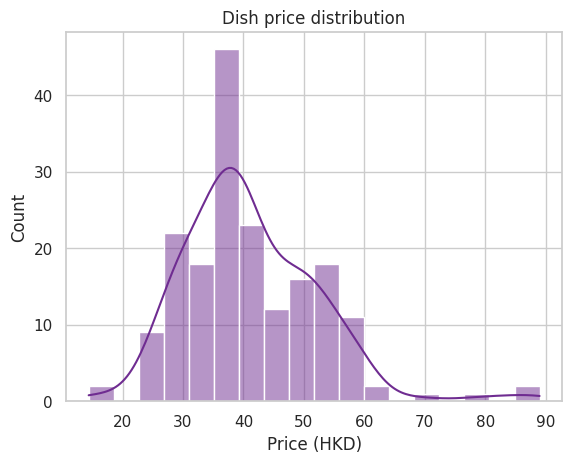

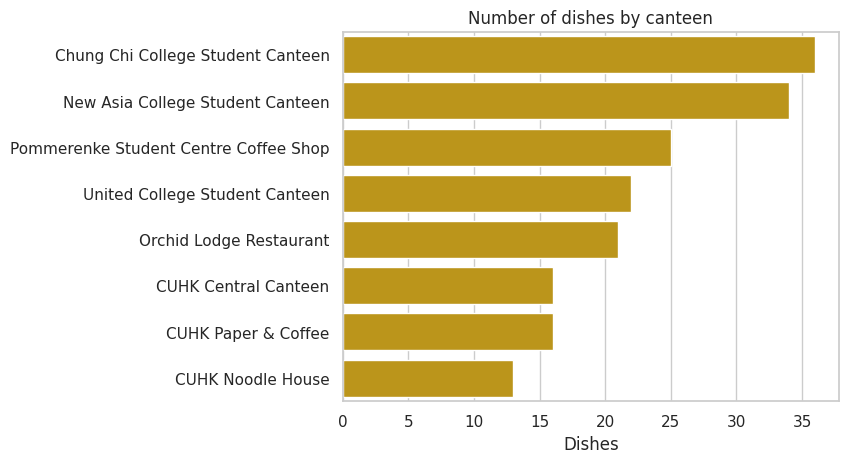

In [55]:
# Item-side profile: menu size and average price by canteen.
canteen_summary = (
    dishes.groupby('canteen')
    .agg(dishes=('dish_id', 'size'), avg_price=('price', 'mean'))
    .sort_values('dishes', ascending=False)
    .reset_index()
)
display(canteen_summary.round(1))

# Demo: what does the price distribution look like?
# This motivates price as a filter/preference dimension, not an MF parameter.
sns.histplot(data=dishes, x='price', bins=18, kde=True, color='#6f2c91')
plt.title('Dish price distribution')
plt.xlabel('Price (HKD)')
plt.show()

# Demo: menu coverage is uneven across canteens.
# This is supply, not a quality ranking; more dishes means more candidate items.
sns.barplot(data=canteen_summary, y='canteen', x='dishes', color='#d6a300')
plt.title('Number of dishes by canteen')
plt.xlabel('Dishes')
plt.ylabel('')
plt.show()

## 3. Ratings, activity, and the long tail

The ratings table has one row per `(user, dish)` pair. A missing pair is not a zero rating; it simply was not observed.

Look for the usual recommender patterns: a concentration of ratings near the middle, uneven user activity, and a long tail of dishes.

### What these plots demonstrate

- The rating histogram shows where the observed scores concentrate. A model that predicts near the global mean can look good on RMSE while still failing to rank dishes differently for different users.
- The line plot shows the **activity long tail**: some users and dishes have many ratings, while most have relatively few.
- This uneven evidence matters for MF: biases and factors for sparse users/items are less reliable, and cold-start cases need a fallback. It is also why CV folds should mix users and groups rather than taking consecutive rows.


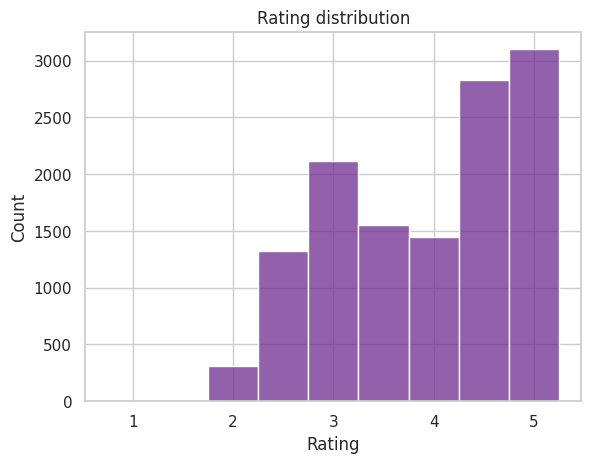

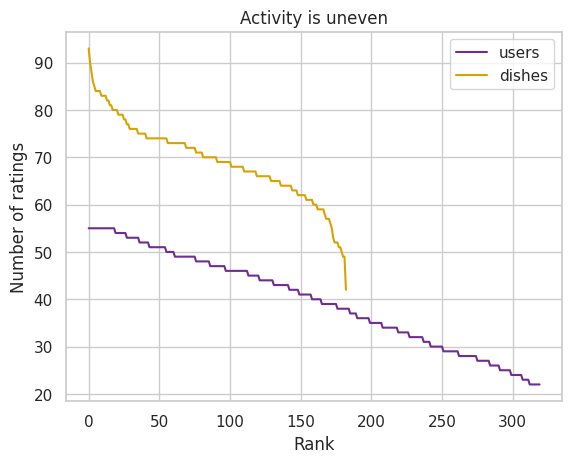

ratings per user: {'count': 320.0, 'mean': 39.6, 'std': 9.9, 'min': 22.0, '25%': 31.0, '50%': 40.0, '75%': 48.0, 'max': 55.0}
ratings per dish: {'count': 183.0, 'mean': 69.3, 'std': 8.5, 'min': 42.0, '25%': 64.0, '50%': 69.0, '75%': 74.0, 'max': 93.0}


In [56]:
# Demo: where do the ratings concentrate?
# RMSE can look good near the mean even when ranking is poor.
sns.histplot(
    data=ratings, x='rating', bins=np.arange(0.75, 5.3, 0.5), color='#6f2c91'
)
plt.title('Rating distribution')
plt.xlabel('Rating')
plt.show()

# Demo: user and dish activity form a long tail.
# Sparse users/items get less reliable factors; this motivates regularization
# and a fallback for cold-start cases.
user_activity = ratings.groupby('user_id').size().sort_values(ascending=False)
dish_activity = ratings.groupby('dish_id').size().sort_values(ascending=False)

sns.lineplot(x=range(len(user_activity)), y=user_activity.to_numpy(),
             label='users', color='#6f2c91')
sns.lineplot(x=range(len(dish_activity)), y=dish_activity.to_numpy(),
             label='dishes', color='#d6a300')
plt.title('Activity is uneven')
plt.xlabel('Rank')
plt.ylabel('Number of ratings')
plt.show()

print('ratings per user:', ratings.groupby('user_id').size().describe().round(1).to_dict())
print('ratings per dish:', ratings.groupby('dish_id').size().describe().round(1).to_dict())

## 4. Do higher-priced canteens rate better?

Each point below is one canteen: its average dish price against its average rating. This is descriptive, not causal—canteens differ in menu mix, users, and item mix. The plot helps us decide whether price is worth using as a filter or preference dimension; it does not prove that higher prices cause better ratings.


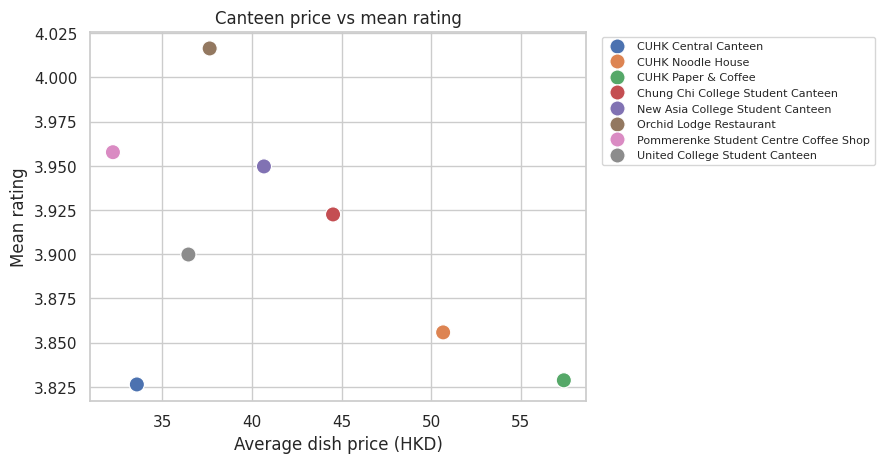

In [57]:
# Canteen-level summary: average price, average rating, and number of ratings.
canteen_quality = (
    ratings.merge(dishes[['dish_id', 'canteen', 'price']], on='dish_id')
    .groupby('canteen')
    .agg(mean_rating=('rating', 'mean'), avg_price=('price', 'mean'), n=('rating', 'size'))
    .reset_index()
)

# Demo: is a more expensive canteen also rated more highly?
# Each point is a canteen; this is descriptive, not causal.
sns.scatterplot(
    data=canteen_quality, x='avg_price', y='mean_rating',
    hue='canteen', s=120
)
plt.title('Canteen price vs mean rating')
plt.xlabel('Average dish price (HKD)')
plt.ylabel('Mean rating')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.show()

## 5. MF through the four questions

| Question | Answer |
|---|---|
| **Model** | $\widehat r_{ui}=\mu+a_u+b_i+p_u^\mathsf{T}q_i$ |
| **Hyperparameters** | $K$ latent coordinates; $\lambda$ regularization strength |
| **Fitting criterion** | squared error on observed training pairs + factor penalty |
| **Learned parameters** | $\mu$, biases $a,b$, factors $P,Q$ |

The canteen domain changes the meaning of a user and an item, not the workflow. The same estimator interface will handle `fit`, `predict`, and `GridSearchCV`.

## 6. A supplied MF estimator

As in the warm-up, the estimator is supplied. Read the public interface, not the ALS internals:

- constructor settings can be searched by `GridSearchCV`;
- `fit` learns attributes ending in `_`;
- `predict` accepts `[user_id, dish_id]` pairs.

In [58]:
class BiasedMF(RegressorMixin, BaseEstimator):
    def __init__(self, n_users, n_items, K=8, lambda_=5.0,
                 n_iters=5, random_state=42):
        self.n_users = n_users
        self.n_items = n_items
        self.K = K
        self.lambda_ = lambda_
        self.n_iters = n_iters
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=int)
        y = np.asarray(y, dtype=float)
        users, items = X[:, 0], X[:, 1]

        self.mu_ = y.mean()
        self.a_ = np.zeros(self.n_users)
        self.b_ = np.zeros(self.n_items)

        rng = np.random.default_rng(self.random_state)
        self.P_ = rng.normal(0, 0.1, size=(self.n_users, self.K))
        self.Q_ = rng.normal(0, 0.1, size=(self.n_items, self.K))

        rows_by_user = [[] for _ in range(self.n_users)]
        rows_by_item = [[] for _ in range(self.n_items)]
        for row, (u, i) in enumerate(X):
            rows_by_user[u].append(row)
            rows_by_item[i].append(row)

        self.seen_users_ = np.array([bool(rows) for rows in rows_by_user])
        self.seen_items_ = np.array([bool(rows) for rows in rows_by_item])
        self.P_[~self.seen_users_] = 0.0
        self.Q_[~self.seen_items_] = 0.0

        for _ in range(self.n_iters):
            for i, rows in enumerate(rows_by_item):
                if not rows:
                    continue
                u = users[rows]
                ridge = Ridge(alpha=self.lambda_, fit_intercept=True)
                ridge.fit(self.P_[u], y[rows] - self.mu_ - self.a_[u])
                self.b_[i] = ridge.intercept_
                self.Q_[i] = ridge.coef_

            for u, rows in enumerate(rows_by_user):
                if not rows:
                    continue
                i = items[rows]
                ridge = Ridge(alpha=self.lambda_, fit_intercept=True)
                ridge.fit(self.Q_[i], y[rows] - self.mu_ - self.b_[i])
                self.a_[u] = ridge.intercept_
                self.P_[u] = ridge.coef_
        return self

    def predict(self, X):
        check_is_fitted(self, 'mu_')
        X = np.asarray(X, dtype=int)
        users, items = X[:, 0], X[:, 1]
        return (
            self.mu_ + self.a_[users] + self.b_[items]
            + np.sum(self.P_[users] * self.Q_[items], axis=1)
        )

## 7. Fit once and compare with a baseline

Use the `train` split for fitting and the `test` split for a single final estimate. The global-mean baseline ignores both user and dish identity; MF should do better on this dataset.

In [59]:
train = ratings[ratings['split'] == 'train'].copy()
test = ratings[ratings['split'] == 'test'].copy()

n_users = int(ratings['user_id'].max()) + 1
n_items = int(ratings['dish_id'].max()) + 1

X_train = train[['user_id', 'dish_id']].to_numpy(dtype=int)
y_train = train['rating'].to_numpy(dtype=float)
X_test = test[['user_id', 'dish_id']].to_numpy(dtype=int)
y_test = test['rating'].to_numpy(dtype=float)

baseline_prediction = np.full(len(y_test), y_train.mean())
print('global-mean test RMSE:', round(root_mean_squared_error(y_test, baseline_prediction), 3))

mf_demo = BiasedMF(n_users=n_users, n_items=n_items, K=2, lambda_=1.0,
                   n_iters=15, random_state=42)
mf_demo.fit(X_train, y_train)
print('MF test RMSE:', round(root_mean_squared_error(y_test, mf_demo.predict(X_test)), 3))
print('training RMSE:', round(root_mean_squared_error(y_train, mf_demo.predict(X_train)), 3))

global-mean test RMSE: 0.913
MF test RMSE: 0.316
training RMSE: 0.27


## 8. Choose $K$ and $\lambda$ with cross-validation

The test split stays untouched during model selection. `GridSearchCV` uses three shuffled folds inside the training rows and selects the setting with the best validation RMSE.

Because the rows are grouped by user, we use `KFold(shuffle=True)` so each fold sees a mix of users and food preferences.


In [60]:
search = GridSearchCV(
    estimator=BiasedMF(n_users=n_users, n_items=n_items, n_iters=8, random_state=42),
    param_grid={'K': [2, 4, 8], 'lambda_': [0.1, 1.0, 10.0]},
    scoring='neg_root_mean_squared_error',
    cv=KFold(n_splits=3, shuffle=True, random_state=42),
    refit=True,
)
search.fit(X_train, y_train)

for K, lambda_, score in zip(
    search.cv_results_['param_K'],
    search.cv_results_['param_lambda_'],
    search.cv_results_['mean_test_score'],
):
    print(f'K={K}, lambda={lambda_}: CV RMSE={-score:.3f}')

print('selected:', search.best_params_)
print(f'best CV RMSE: {-search.best_score_:.3f}')
print('test RMSE of refitted model:',
      round(root_mean_squared_error(y_test, search.best_estimator_.predict(X_test)), 3))

K=2, lambda=0.1: CV RMSE=0.350
K=2, lambda=1.0: CV RMSE=0.350
K=2, lambda=10.0: CV RMSE=0.630
K=4, lambda=0.1: CV RMSE=0.411
K=4, lambda=1.0: CV RMSE=0.369
K=4, lambda=10.0: CV RMSE=0.627
K=8, lambda=0.1: CV RMSE=0.555
K=8, lambda=1.0: CV RMSE=0.392
K=8, lambda=10.0: CV RMSE=0.628
selected: {'K': 2, 'lambda_': 0.1}
best CV RMSE: 0.350
test RMSE of refitted model: 0.316


## 9. Top-N recommendations for one student

For a chosen user, score every dish, remove dishes the student has already rated, and show the highest-predicted dishes. This is the step that turns rating prediction into a product feature.

In [61]:
def recommend_for_user(model, user_id, k=8, exclude_seen=True):
    candidate_dishes = dishes.copy()
    if exclude_seen:
        seen = set(ratings.loc[ratings['user_id'] == user_id, 'dish_id'])
        candidate_dishes = candidate_dishes[~candidate_dishes['dish_id'].isin(seen)]
    pairs = np.column_stack([
        np.full(len(candidate_dishes), user_id),
        candidate_dishes['dish_id'].to_numpy(),
    ])
    candidate_dishes = candidate_dishes.assign(
        predicted_rating=np.clip(model.predict(pairs), 1.0, 5.0)
    )
    return (
        candidate_dishes
        .sort_values('predicted_rating', ascending=False)
        .head(k)
        [['dish', 'canteen', 'price', 'category', 'predicted_rating']]
    )

best_mf = search.best_estimator_
example_user = 237
display(users.loc[users.user_id == example_user, ['user_id', 'food_preference']])
display(recommend_for_user(best_mf, example_user).round(2))

,user_id,food_preference
237,237,Noodles


,dish,canteen,price,category,predicted_rating
104,雞扒古列魚柳煎蛋扁意粉,Pommerenke Student Centre Coffee Shop,36.2,Noodles,4.92
39,三拼米線,United College Student Canteen,40.0,Noodles,4.90
116,關東煮牛肉湯烏冬,CUHK Paper & Coffee,59.0,Noodles,4.88
156,一餸兩餸雲南米線,Chung Chi College Student Canteen,34.0,Noodles,4.87
157,兩餸雲南米線,Chung Chi College Student Canteen,40.0,Noodles,4.86
135,蜂蜜香草雞髀拌芝士薯蓉,Orchid Lodge Restaurant,39.0,Others,4.86
8,慢煮雞胸肉讚岐烏冬配麻藥蛋(凍食),New Asia College Student Canteen,58.0,Noodles,4.85
107,炸雞髀扁意粉,Pommerenke Student Centre Coffee Shop,31.6,Noodles,4.84


## 10. Do user factors reveal taste groups?

K-means returns cluster IDs `0..5`; those IDs are not meaningful names. To name a cluster **without using the synthetic `food_preference` column**, we compute the model's average predicted rating for every dish category among that cluster's users and use the highest-scoring category as the label. The `food_preference` column is used only afterward to check whether the clusters recover the generator's labels.

This is exploratory and the data are synthetic: a clear result here shows that MF can recover the generative structure, not that real students form six groups.


In [65]:
mf_k2 = BiasedMF(
    n_users=n_users, n_items=n_items,
    K=2, lambda_=0.1, n_iters=15, random_state=42,
)
mf_k2.fit(X_train, y_train)
P_user = mf_k2.P_

cluster_labels = KMeans(
    n_clusters=6, n_init=30, random_state=42
).fit_predict(P_user)


### Naming and visualizing the clusters

K-means only gives cluster IDs. We name each cluster by the dish category with the highest average **predicted** rating among its users; the known `food_preference` column is not used for naming.


,users
cluster_name,
Burgers & Sandwiches,53
Cafe & Dessert,53
Noodles,54
Rice,54
Snacks,53
Vegetarian,53


food_preference,Burgers & Sandwiches,Cafe & Dessert,Noodles,Rice,Snacks,Vegetarian & lighter
cluster_name,,,,,,
Burgers & Sandwiches,53,0,0,0,0,0
Cafe & Dessert,0,53,0,0,0,0
Noodles,0,0,54,0,0,0
Rice,0,0,0,54,0,0
Snacks,0,0,0,0,53,0
Vegetarian,0,0,0,0,0,53


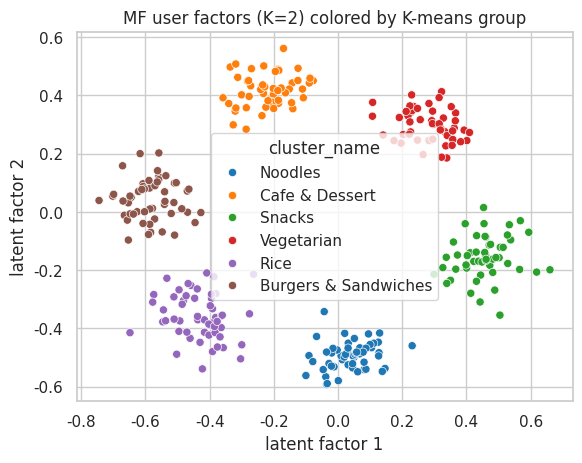

In [66]:
# Name each cluster from its predicted category profile.
def top_category(cluster):
    user_ids = user_groups.loc[user_groups['cluster'] == cluster, 'user_id'].to_numpy()
    pairs = np.column_stack([
        np.repeat(user_ids, len(dishes)),
        np.tile(dishes['dish_id'].to_numpy(), len(user_ids)),
    ])
    scored = pd.DataFrame({'dish_id': pairs[:, 1], 'score': mf_k2.predict(pairs)})
    return (
        scored.merge(dishes[['dish_id', 'category']], on='dish_id')
        .groupby('category')['score'].mean()
        .idxmax()
    )

cluster_names = {
    cluster: top_category(cluster)
    for cluster in sorted(user_groups['cluster'].unique())
}
user_groups['cluster_name'] = user_groups['cluster'].map(cluster_names)

display(user_groups.groupby('cluster_name').size().to_frame('users'))
display(pd.crosstab(user_groups['cluster_name'], user_groups['food_preference']))

plot_data = user_groups.assign(
    factor_1=P_user[:, 0], factor_2=P_user[:, 1]
)
sns.scatterplot(
    data=plot_data, x='factor_1', y='factor_2',
    hue='cluster_name', palette='tab10', s=35,
)
plt.title('MF user factors (K=2) colored by K-means group')
plt.xlabel('latent factor 1')
plt.ylabel('latent factor 2')
plt.show()

The names above are **model-derived category labels**, not the synthetic food-preference labels. The `food_preference` column was used only to compute the ARI and the crosstab.

In this run, K-means recovers the six synthetic food-preference groups almost perfectly: the silhouette is about 0.71 and the adjusted Rand index is about 0.98. The factors separate noodles, rice, burgers/sandwiches, cafe items, vegetarian food, and snacks.

That is a property of the generated data, not evidence about real CUHK students. In a real dataset, clusters would be noisier and might not align with menu categories.


## 11. Where this goes next

The same table can feed a simple website: choose a student profile, show the top dishes, and add a canteen or price filter. The recommendation logic remains the MF model; the website only presents the results.

**Real vs simulated:** the menu and prices are real CUHK canteen data. The ratings are synthetic and exist to make the classroom workflow reproducible. Do not present the predicted scores as evidence about real student preferences.

## Exit ticket

1. Which parts of this dataset are real, and which are simulated?
2. Why is the rating matrix sparse, and why does MF use only observed entries?
3. What does `GridSearchCV` choose, and which data does it leave for the final test estimate?
4. For a student who has already rated a dish, should we recommend that dish again? Why or why not?